# Ejercicios de práctica del segundo parcial
Solución a la lista de ejercicios a programar para la materia de Simulación II, con el profesor Salat Figols, en el grupo 8MV1.

## Ejercicio 1
---

### Inciso A
---

In [64]:
#Librerías a usar
import math
import statistics
import random
import numpy as np
from numba import njit
import matplotlib.pyplot as plt
from tabulate import tabulate
# 1. Definición de parámetros del problema
P0 = 10.0       # Precio inicial
K = 11.0        # Precio de ejercicio
T = 50.0        # Tiempo al vencimiento
mu = 0.002      # Deriva
sigma = 0.01    # Volatilidad
N = 1000000      # Número de simulaciones

# 2. Generación de variables normales estándar Z
# Nota: numpy.random.standard_normal es la versión vectorizada de random.gauss
np.random.seed(42)  # Semilla para reproducibilidad
Z = np.random.standard_normal(N)

# 3. Cálculo del precio final P_T usando la solución exacta del GBM
# Usamos np.exp que es la versión vectorizada de math.exp
P_T = P0 * np.exp((mu - 0.5 * sigma**2) * T + sigma * math.sqrt(T) * Z)

# 4. Cálculo del Payoff (Ganancia) de la opción Call
# np.maximum es la versión vectorizada de max()
payoff_base = np.maximum(P_T - K, 0)

# 5. Estimación de la esperanza (promedio)
valor_esperado_base = np.mean(payoff_base)

# 6. Cálculo de la varianza del estimador (usando la varianza muestral)
varianza_base = np.var(payoff_base, ddof=1)

print(f"Valor esperado de la ganancia: {valor_esperado_base:.6f}")
print(f"Varianza del estimador base:   {varianza_base:.6f}")

Valor esperado de la ganancia: 0.336981
Varianza del estimador base:   0.242453


### Inciso B
---

In [10]:
# 1. Generación de variables antitéticas
Z_anti = -Z

# 2. Cálculo de precios finales para ambas simulaciones
P_T_1 = P0 * np.exp((mu - 0.5 * sigma**2) * T + sigma * math.sqrt(T) * Z)
P_T_2 = P0 * np.exp((mu - 0.5 * sigma**2) * T + sigma * math.sqrt(T) * Z_anti)

# 3. Cálculo de los payoffs individuales
payoff_1 = np.maximum(P_T_1 - K, 0)
payoff_2 = np.maximum(P_T_2 - K, 0)

# 4. El nuevo estimador es el promedio de los payoffs antitéticos
payoff_anti = (payoff_1 + payoff_2) / 2.0

# 5. Estimación de la esperanza y varianza con variables antitéticas
valor_esperado_anti = np.mean(payoff_anti)
varianza_anti = np.var(payoff_anti, ddof=1)

# 6. Cálculo del porcentaje de reducción de varianza
reduccion = (1 - varianza_anti / varianza_base) * 100

print(f"Valor esperado (antitético): {valor_esperado_anti:.6f}")
print(f"Varianza (antitética):       {varianza_anti:.6f}")
print(f"Reducción de varianza:       {reduccion:.2f}%")

Valor esperado (antitético): 0.337655
Varianza (antitética):       0.064518
Reducción de varianza:       73.39%


### Gráficas
---

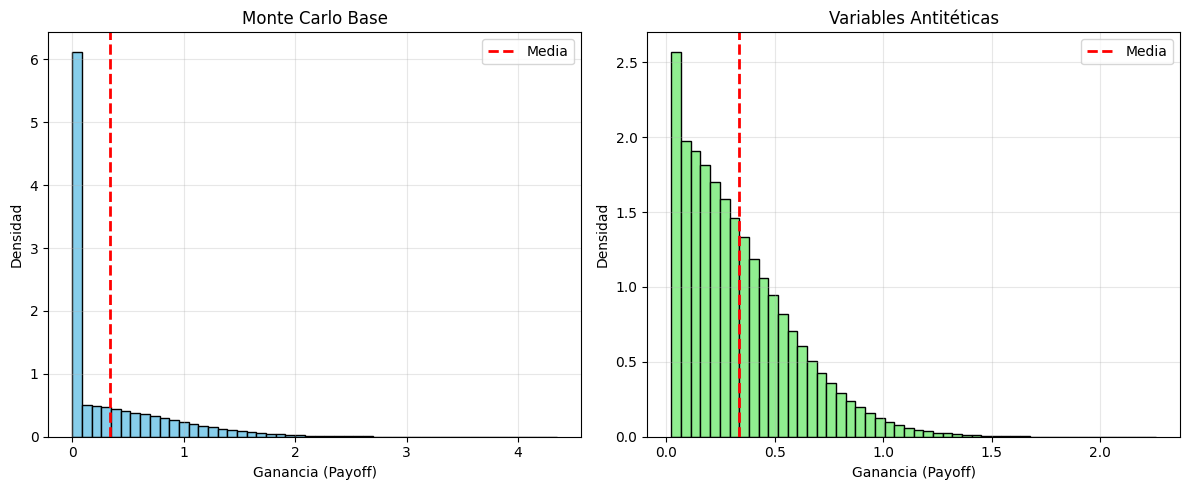

In [11]:
# Configuración de la figura
plt.figure(figsize=(12, 5))


# Histograma del estimador base
plt.subplot(1, 2, 1)
plt.hist(payoff_base, bins=50, color='skyblue', edgecolor='black', density=True)
plt.title('Monte Carlo Base')
plt.xlabel('Ganancia (Payoff)')
plt.ylabel('Densidad')
plt.axvline(valor_esperado_base, color='red', linestyle='dashed', linewidth=2, label='Media')
plt.legend()
plt.grid(alpha=0.3)

# Histograma del estimador antitético
plt.subplot(1, 2, 2)
plt.hist(payoff_anti, bins=50, color='lightgreen', edgecolor='black', density=True)
plt.title('Variables Antitéticas')
plt.xlabel('Ganancia (Payoff)')
plt.ylabel('Densidad')
plt.axvline(valor_esperado_anti, color='red', linestyle='dashed', linewidth=2, label='Media')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Ejercicio 2

### Inciso A
---

In [29]:
# ==========================================
# 0. Parámetros Generales
# ==========================================
N = 100000      
K = 100          
np.random.seed(42) 

def evaluar_integral(X):
    return 2.0 * np.exp(-X**2)
# ==========================================
# Inciso A) Monte Carlo Base
# ==========================================
U_base = np.random.uniform(0, 1, N)
X_base = 2.0 * U_base
Y_base = evaluar_integral(X_base)

media_base = statistics.mean(Y_base)
# Varianza de las muestras (equivalente a la varianza del estimador multiplicada por N)
var_base = statistics.variance(Y_base)

### Inciso B
---

In [ ]:
# ==========================================
# Inciso B) Variables Antitéticas
# ==========================================
X_1 = 2.0 * U_base
X_2 = 2.0 * (1.0 - U_base) 

Y_anti = (evaluar_integral(X_1) + evaluar_integral(X_2)) / 2.0

media_anti = statistics.mean(Y_anti)
var_anti = statistics.variance(Y_anti)

### Inciso C
---

In [31]:
# ==========================================
# Inciso C) Variables de Control
# ==========================================
C_control = X_base**2
media_teorica_C = 4.0 / 3.0

cov_matrix = np.cov(Y_base, C_control)
beta = cov_matrix[0, 1] / cov_matrix[1, 1]

Y_control = Y_base - beta * (C_control - media_teorica_C)

media_control = statistics.mean(Y_control)
var_control = statistics.variance(Y_control)

### Inciso D
---

In [32]:
#==========================================
# Inciso D) Muestreo Estratificado (CORREGIDO)
# ==========================================
N_estrato = N // K
varianzas_estratos = [] # Aquí guardaremos la varianza de CADA estrato
Y_strat_total = np.zeros(N) # Solo para el gráfico final

for i in range(K):
    # Generamos uniformes en el estrato i
    U_estrato = np.random.uniform(i/K, (i+1)/K, N_estrato)
    X_estrato = 2.0 * U_estrato
    Y_estrato = evaluar_integral(X_estrato)
    
    # Guardamos los datos para la gráfica
    Y_strat_total[i*N_estrato : (i+1)*N_estrato] = Y_estrato
    
    # CALCULAMOS LA VARIANZA DENTRO DE ESTE ESTRATO
    var_k = statistics.variance(Y_estrato)
    varianzas_estratos.append(var_k)

media_strat = statistics.mean(Y_strat_total)

# La varianza efectiva del estimador estratificado es el promedio de las varianzas internas
var_strat = sum(varianzas_estratos) / K

# ==========================================
# Creación de Tabla Comparativa (con tabulate)
# ==========================================
red_anti = (1 - var_anti / var_base) * 100
red_control = (1 - var_control / var_base) * 100
red_strat = (1 - var_strat / var_base) * 100

tabla_datos = [
    ["Monte Carlo Base", f"{media_base:.6f}", f"{var_base:.8f}", "-"],
    ["Antitéticas", f"{media_anti:.6f}", f"{var_anti:.8f}", f"{red_anti:.2f}%"],
    ["Variables de Control", f"{media_control:.6f}", f"{var_control:.8f}", f"{red_control:.2f}%"],
    ["Estratificado (K=10)", f"{media_strat:.6f}", f"{var_strat:.8f}", f"{red_strat:.2f}%"]
]

print("================================================================")
print("     RESULTADOS DE LA INTEGRAL Y REDUCCIÓN DE VARIANZA")
print("================================================================")
print(tabulate(tabla_datos, 
               headers=["Método", "Valor Estimado", "Varianza Efectiva", "% Reducción Var."], 
               tablefmt="grid", 
               stralign="center"))

print(f"\nValor Real (para referencia): {0.8820813907:.6f}")

     RESULTADOS DE LA INTEGRAL Y REDUCCIÓN DE VARIANZA
+----------------------+------------------+---------------------+--------------------+
|        Método        |   Valor Estimado |   Varianza Efectiva |  % Reducción Var.  |
+======================+==================+=====================+====================+
|   Monte Carlo Base   |         0.882874 |           0.475158  |         -          |
+----------------------+------------------+---------------------+--------------------+
|     Antitéticas      |         0.881956 |           0.0104285 |       97.81%       |
+----------------------+------------------+---------------------+--------------------+
| Variables de Control |         0.881376 |           0.0758732 |       84.03%       |
+----------------------+------------------+---------------------+--------------------+
| Estratificado (K=10) |         0.882051 |           4.178e-05 |       99.99%       |
+----------------------+------------------+---------------------+----------

### Gráficos
---

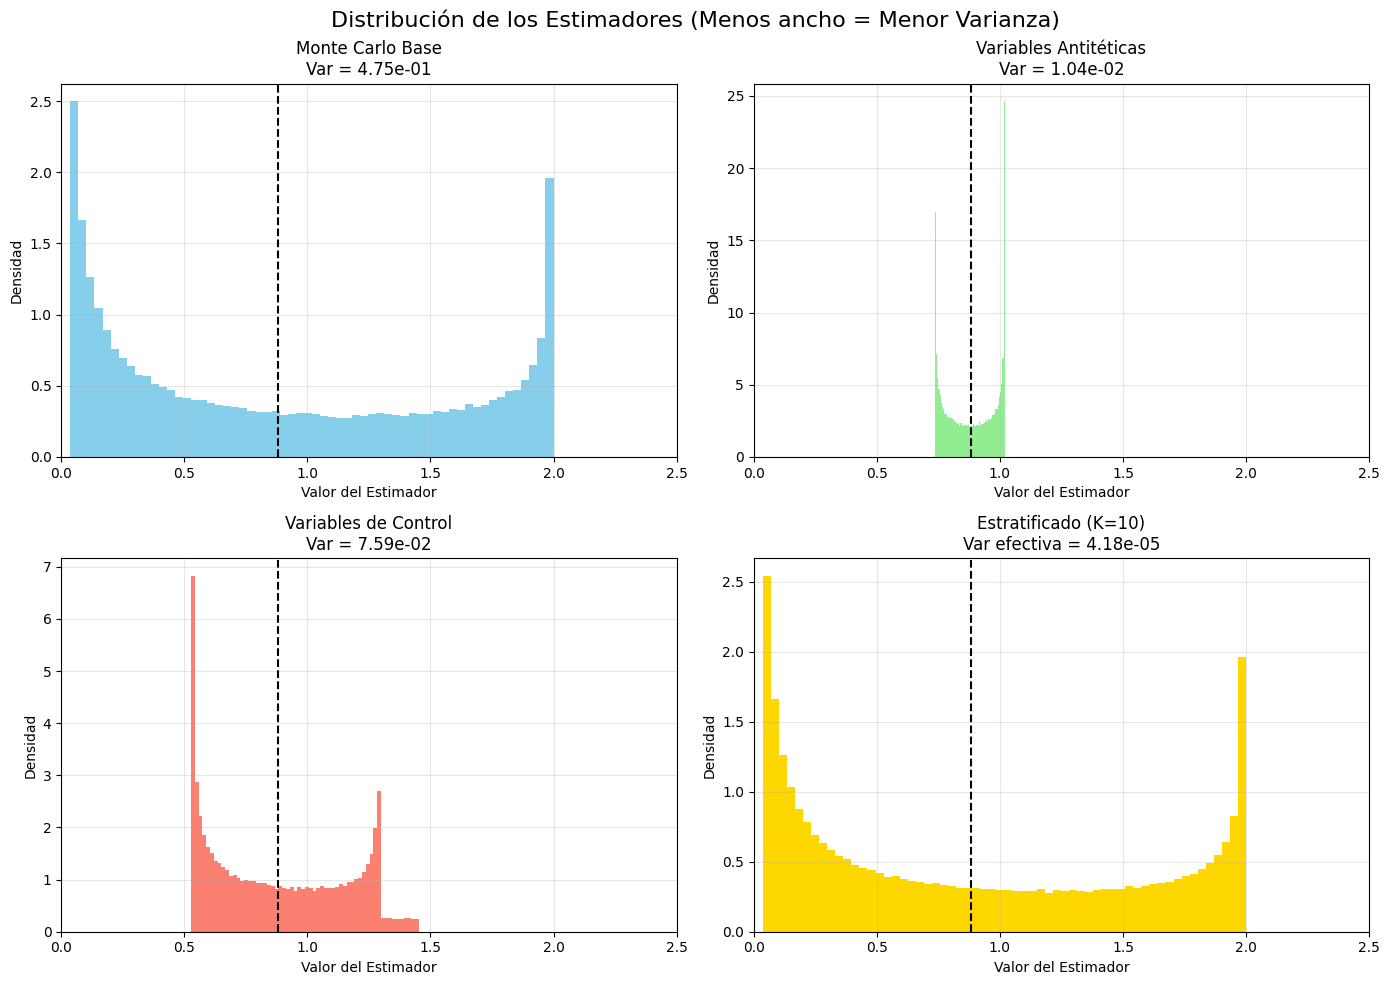

In [33]:
# ==========================================
# Gráficos de los Histogramas
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Distribución de los Estimadores (Menos ancho = Menor Varianza)', fontsize=16)

axes[0, 0].hist(Y_base, bins=60, color='skyblue', density=True)
axes[0, 0].set_title(f'Monte Carlo Base\nVar = {var_base:.2e}')
axes[0, 0].set_xlim(0, 2.5)

axes[0, 1].hist(Y_anti, bins=60, color='lightgreen', density=True)
axes[0, 1].set_title(f'Variables Antitéticas\nVar = {var_anti:.2e}')
axes[0, 1].set_xlim(0, 2.5)

axes[1, 0].hist(Y_control, bins=60, color='salmon', density=True)
axes[1, 0].set_title(f'Variables de Control\nVar = {var_control:.2e}')
axes[1, 0].set_xlim(0, 2.5)

axes[1, 1].hist(Y_strat_total, bins=60, color='gold', density=True)
axes[1, 1].set_title(f'Estratificado (K=10)\nVar efectiva = {var_strat:.2e}')
axes[1, 1].set_xlim(0, 2.5)

for ax in axes.flat:
    ax.set_xlabel('Valor del Estimador')
    ax.set_ylabel('Densidad')
    ax.axvline(0.88208, color='black', linestyle='dashed', label='Valor Real')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Ejercicio 3
---

### Inciso A
---

<>:25: SyntaxWarning: invalid escape sequence '\s'
<>:26: SyntaxWarning: invalid escape sequence '\s'
<>:25: SyntaxWarning: invalid escape sequence '\s'
<>:26: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1448/3057593495.py:25: SyntaxWarning: invalid escape sequence '\s'
  plt.title('Distribución de $\sqrt{X}$ (Monte Carlo Base)')
/tmp/ipykernel_1448/3057593495.py:26: SyntaxWarning: invalid escape sequence '\s'
  plt.xlabel('$\sqrt{X}$')


Valor esperado estimado: 0.512114
Varianza del estimador:  7.134375e-02


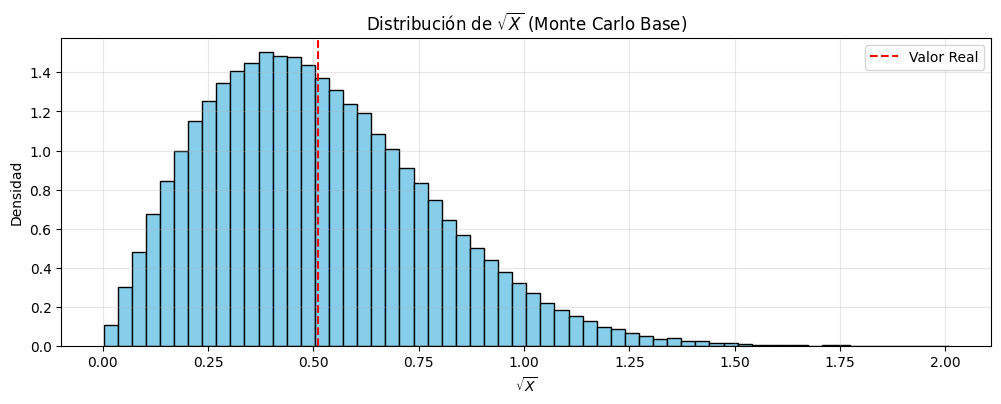

In [34]:
# 0. Parámetros globales
N = 100000
np.random.seed(42)
valor_real = math.sqrt(math.pi) / (2 * math.sqrt(3)) # Valor analítico exacto

# Generamos U ~ Uniforme(0,1)
U_base = np.random.uniform(0, 1, N)

# Transformada inversa: X = -ln(U)/3
X_base = -np.log(U_base) / 3.0

# Evaluamos la función de interés: Y = sqrt(X)
Y_base = np.sqrt(X_base)

# Estadísticos
media_base = statistics.mean(Y_base)
var_base = statistics.variance(Y_base)

print(f"Valor esperado estimado: {media_base:.6f}")
print(f"Varianza del estimador:  {var_base:.6e}")

# Gráfica
plt.figure(figsize=(12, 4))
plt.hist(Y_base, bins=60, color='skyblue', edgecolor='black', density=True)
plt.title('Distribución de $\sqrt{X}$ (Monte Carlo Base)')
plt.xlabel('$\sqrt{X}$')
plt.ylabel('Densidad')
plt.axvline(valor_real, color='red', linestyle='dashed', label='Valor Real')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Inciso B
---

Valor esperado estimado: 0.511495
Varianza del estimador:  1.874735e-03
Reducción de varianza:   97.37%


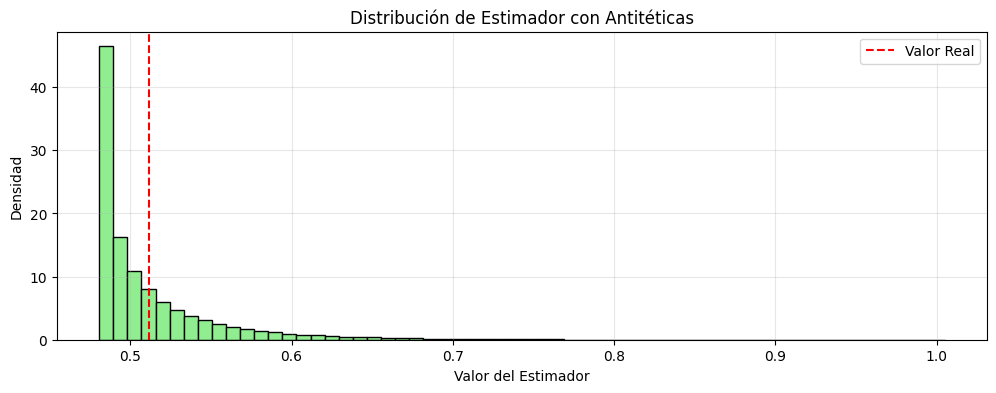

In [35]:
# Generamos el par antitético de uniformes
X_anti_1 = -np.log(U_base) / 3.0
X_anti_2 = -np.log(1.0 - U_base) / 3.0

# Evaluamos y promediamos los pares
Y_anti_1 = np.sqrt(X_anti_1)
Y_anti_2 = np.sqrt(X_anti_2)
Y_anti = (Y_anti_1 + Y_anti_2) / 2.0

# Estadísticos
media_anti = statistics.mean(Y_anti)
var_anti = statistics.variance(Y_anti)
red_anti = (1 - var_anti / var_base) * 100

print(f"Valor esperado estimado: {media_anti:.6f}")
print(f"Varianza del estimador:  {var_anti:.6e}")
print(f"Reducción de varianza:   {red_anti:.2f}%")

# Gráfica
plt.figure(figsize=(12, 4))
plt.hist(Y_anti, bins=60, color='lightgreen', edgecolor='black', density=True)
plt.title('Distribución de Estimador con Antitéticas')
plt.xlabel('Valor del Estimador')
plt.ylabel('Densidad')
plt.axvline(valor_real, color='red', linestyle='dashed', label='Valor Real')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Inciso C
---

Beta estimado:           0.766226
Valor esperado estimado: 0.511907
Varianza del estimador:  6.079252e-03
Reducción de varianza:   91.48%
Beta analítico exacto:   0.767495


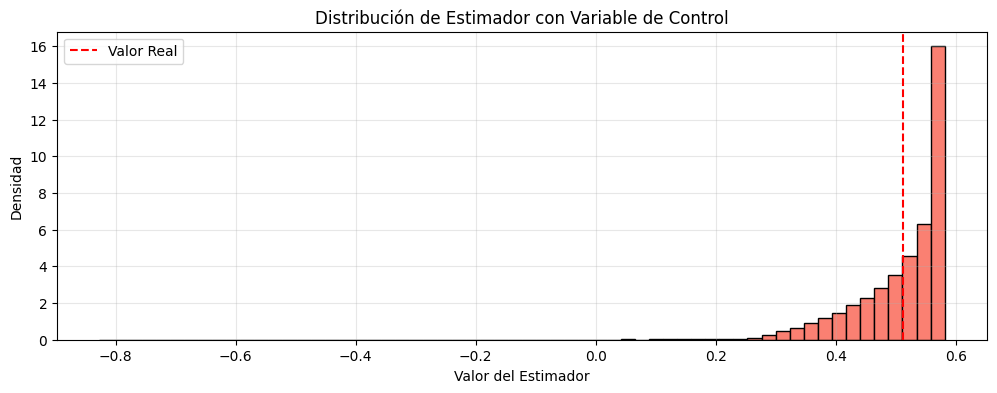

In [36]:
# Variable de control y su media teórica
C_control = X_base
media_teorica_C = 1.0 / 3.0

# Cálculo del coeficiente beta óptimo
cov_matrix = np.cov(Y_base, C_control)
covarianza = cov_matrix[0, 1]
var_C = cov_matrix[1, 1]
beta = covarianza / var_C

# Estimador corregido
Y_control = Y_base - beta * (C_control - media_teorica_C)

# Estadísticos
media_control = statistics.mean(Y_control)
var_control = statistics.variance(Y_control)
red_control = (1 - var_control / var_base) * 100

print(f"Beta estimado:           {beta:.6f}")
print(f"Valor esperado estimado: {media_control:.6f}")
print(f"Varianza del estimador:  {var_control:.6e}")
print(f"Reducción de varianza:   {red_control:.2f}%")

# Verificación Analítica
# Teóricamente, beta = Cov(sqrt(X), X) / Var(X) = (E[X^1.5] - E[sqrt(X)]E[X]) / (1/9)
E_X_15 = math.sqrt(math.pi) / (4 * math.sqrt(3))
beta_teorico = (E_X_15 - valor_real * (1/3)) / (1/9)
print(f"Beta analítico exacto:   {beta_teorico:.6f}")

# Gráfica
plt.figure(figsize=(12, 4))
plt.hist(Y_control, bins=60, color='salmon', edgecolor='black', density=True)
plt.title('Distribución de Estimador con Variable de Control')
plt.xlabel('Valor del Estimador')
plt.ylabel('Densidad')
plt.axvline(valor_real, color='red', linestyle='dashed', label='Valor Real')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Inciso D
---

Mejores parámetros -> mu = 0.35, sigma = 0.48
Valor esperado estimado: 0.509576 (Real: 0.511663)
Varianza del estimador:  3.646240e-02
Reducción de varianza:   48.89%


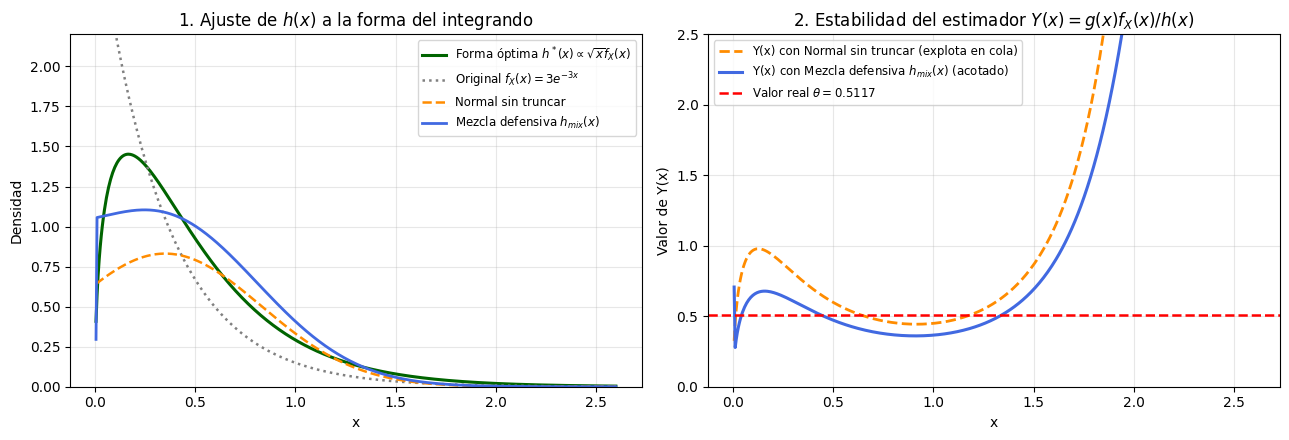

In [62]:
# Parámetros del intervalo y peso de la mezcla defensiva h_mix(x)
a, b = 0.01, 2.20
w = 0.90

mejor_var = float('inf')
mejor_mu, mejor_sigma = 0.0, 0.0

Z_pool = np.random.normal(0, 1, int(N * 1.8))
U_mezcla_busq = np.random.uniform(0, 1, N)
U_exp_busq = np.random.uniform(0, 1, N)
X_exp_busq = -np.log(1.0 - U_exp_busq) / 3.0

# 1. Búsqueda de parámetros para la mezcla defensiva h_mix(x)
for mu_p in [0.35, 0.40, 0.45, 0.50, 0.55]:
    for sigma_p in [0.32, 0.36, 0.40, 0.44, 0.48]:
        X_cand = mu_p + sigma_p * Z_pool
        X_trunc_cand = X_cand[(X_cand > a) & (X_cand < b)][:N]

        # Muestra de tamaño N siguiendo h_mix(x) = w * h_trunc(x) + (1 - w) * f_X(x)
        X_mix = np.where(U_mezcla_busq < w, X_trunc_cand, X_exp_busq)

        z_ab = 0.5 * (
            math.erf((b - mu_p) / (sigma_p * math.sqrt(2)))
            - math.erf((a - mu_p) / (sigma_p * math.sqrt(2)))
        )

        f_x = 3.0 * np.exp(-3.0 * X_mix)
        g_norm = (1.0 / (sigma_p * math.sqrt(2 * math.pi))) * np.exp(-((X_mix - mu_p)**2) / (2 * sigma_p**2))
        h_trunc = np.where((X_mix > a) & (X_mix < b), g_norm / z_ab, 0.0)
        h_mix = w * h_trunc + (1.0 - w) * f_x

        # Evaluamos la definición: Y = g(x) * f_X(x) / h_mix(x)
        Y_cand = np.sqrt(X_mix) * (f_x / h_mix)
        var_temp = statistics.variance(Y_cand)

        if var_temp < mejor_var:
            mejor_var = var_temp
            mejor_mu, mejor_sigma = mu_p, sigma_p

print(f"Mejores parámetros -> mu = {mejor_mu}, sigma = {mejor_sigma}")

# 2. Simulación final con los mejores parámetros
np.random.seed(123)
Z_final_pool = np.random.normal(0, 1, int(N * 1.8))
X_final_cand = mejor_mu + mejor_sigma * Z_final_pool
X_final_trunc = X_final_cand[(X_final_cand > a) & (X_final_cand < b)][:N]

U_mezcla_f = np.random.uniform(0, 1, N)
U_exp_f = np.random.uniform(0, 1, N)
X_final_exp = -np.log(1.0 - U_exp_f) / 3.0

X_final = np.where(U_mezcla_f < w, X_final_trunc, X_final_exp)

z_ab_f = 0.5 * (
    math.erf((b - mejor_mu) / (mejor_sigma * math.sqrt(2)))
    - math.erf((a - mejor_mu) / (mejor_sigma * math.sqrt(2)))
)

f_x_f = 3.0 * np.exp(-3.0 * X_final)
g_norm_f = (1.0 / (mejor_sigma * math.sqrt(2 * math.pi))) * np.exp(-((X_final - mejor_mu)**2) / (2 * mejor_sigma**2))
h_trunc_f = np.where((X_final > a) & (X_final < b), g_norm_f / z_ab_f, 0.0)
h_mix_f = w * h_trunc_f + (1.0 - w) * f_x_f

Y_final = np.sqrt(X_final) * (f_x_f / h_mix_f)

media_is = statistics.mean(Y_final)
var_is = statistics.variance(Y_final)
red_is = (1 - var_is / var_base) * 100

print(f"Valor esperado estimado: {media_is:.6f} (Real: {valor_real:.6f})")
print(f"Varianza del estimador:  {var_is:.6e}")
print(f"Reducción de varianza:   {red_is:.2f}%")

# 3. Visualización comparativa del ajuste de h_mix(x) y estabilidad de Y(x)
x_grid = np.linspace(0.005, 2.6, 500)

f_x_g = 3.0 * np.exp(-3.0 * x_grid)
g_x_g = np.sqrt(x_grid)
gf_x_g = g_x_g * f_x_g

h_normal_g = (1.0 / (mejor_sigma * math.sqrt(2 * math.pi))) * np.exp(-((x_grid - mejor_mu)**2) / (2 * mejor_sigma**2))
h_trunc_g = np.where((x_grid > a) & (x_grid < b), h_normal_g / z_ab_f, 0.0)
h_mix_g = w * h_trunc_g + (1.0 - w) * f_x_g

Y_curva_normal = gf_x_g / h_normal_g
Y_curva_mix = gf_x_g / h_mix_g

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: Comparación de densidades frente a la forma óptima
ax1.plot(x_grid, gf_x_g / valor_real, color='darkgreen', linewidth=2.2, label='Forma óptima $h^*(x) \\propto \\sqrt{x}f_X(x)$')
ax1.plot(x_grid, f_x_g, color='gray', linestyle=':', linewidth=1.8, label='Original $f_X(x) = 3e^{-3x}$')
ax1.plot(x_grid, h_normal_g, color='darkorange', linestyle='--', linewidth=1.8, label='Normal sin truncar')
ax1.plot(x_grid, h_mix_g, color='royalblue', linewidth=2.0, label='Mezcla defensiva $h_{mix}(x)$')
ax1.set_title('1. Ajuste de $h(x)$ a la forma del integrando')
ax1.set_xlabel('x')
ax1.set_ylabel('Densidad')
ax1.set_ylim(0, 2.2)
ax1.legend(fontsize=8.5)
ax1.grid(alpha=0.3)

# Panel 2: Estabilidad del cociente Y(x) = g(x)f_X(x)/h(x)
ax2.plot(x_grid, Y_curva_normal, color='darkorange', linestyle='--', linewidth=2.0, label='Y(x) con Normal sin truncar (explota en cola)')
ax2.plot(x_grid, Y_curva_mix, color='royalblue', linewidth=2.2, label='Y(x) con Mezcla defensiva $h_{mix}(x)$ (acotado)')
ax2.axhline(valor_real, color='red', linestyle='dashed', linewidth=1.8, label=f'Valor real $\\theta = {valor_real:.4f}$')
ax2.set_title('2. Estabilidad del estimador $Y(x) = g(x)f_X(x)/h(x)$')
ax2.set_xlabel('x')
ax2.set_ylabel('Valor de Y(x)')
ax2.set_ylim(0, 2.5)
ax2.legend(fontsize=8.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Tabla comparativa
---

In [63]:
tabla_datos = [
    ["Monte Carlo Base", f"{media_base:.6f}", f"{var_base:.6e}", "-"],
    ["Antitéticas", f"{media_anti:.6f}", f"{var_anti:.6e}", f"{red_anti:.2f}%"],
    ["Variables de Control", f"{media_control:.6f}", f"{var_control:.6e}", f"{red_control:.2f}%"],
    ["Muestreo Importancia", f"{media_is:.6f}", f"{var_is:.6e}", f"{red_is:.2f}%"]
]

print("\n" + "="*80)
print("                 COMPARATIVA DE MÉTODOS")
print("="*80)
print(tabulate(tabla_datos, headers=["Método", "Estimación", "Varianza", "Reducción %"], tablefmt="grid"))
print(f"\nValor Real: {valor_real:.6f}")


                 COMPARATIVA DE MÉTODOS
+----------------------+--------------+------------+---------------+
| Método               |   Estimación |   Varianza | Reducción %   |
+======================+==============+============+===============+
| Monte Carlo Base     |     0.512114 | 0.0713437  | -             |
+----------------------+--------------+------------+---------------+
| Antitéticas          |     0.511495 | 0.00187473 | 97.37%        |
+----------------------+--------------+------------+---------------+
| Variables de Control |     0.511907 | 0.00607925 | 91.48%        |
+----------------------+--------------+------------+---------------+
| Muestreo Importancia |     0.509576 | 0.0364624  | 48.89%        |
+----------------------+--------------+------------+---------------+

Valor Real: 0.511663


## Ejercicio 4
---

### Inciso A
---

In [66]:
# Parámetros del problema
P0 = 5.0
mu = 0.002
sigma = 0.01
meta = 10.4
N = 20000  # Total de trayectorias simuladas

@njit
def simular_mc_crudo(N, P0, mu, sigma, meta, semilla=42):
    random.seed(semilla)
    dias = np.empty(N, dtype=np.float64)
    drift = mu - 0.5 * (sigma ** 2)

    for i in range(N):
        P = P0
        t = 0
        while P <= meta:
            Z = random.gauss(0.0, 1.0)
            P = P * math.exp(drift + sigma * Z)
            t += 1
        dias[i] = t

    return dias

# Ejecución de la simulación base
dias_mc = simular_mc_crudo(N, P0, mu, sigma, meta, semilla=42)

media_mc = np.mean(dias_mc)
var_muestral_mc = np.var(dias_mc, ddof=1)
var_est_mc = var_muestral_mc / N

print(f"Días esperados estimados: {media_mc:.4f}")
print(f"Varianza del estimador:   {var_est_mc:.6f} (Varianza muestral: {var_muestral_mc:.2f})")

Días esperados estimados: 378.9127
Varianza del estimador:   0.491263 (Varianza muestral: 9825.25)


### Gráficas
---

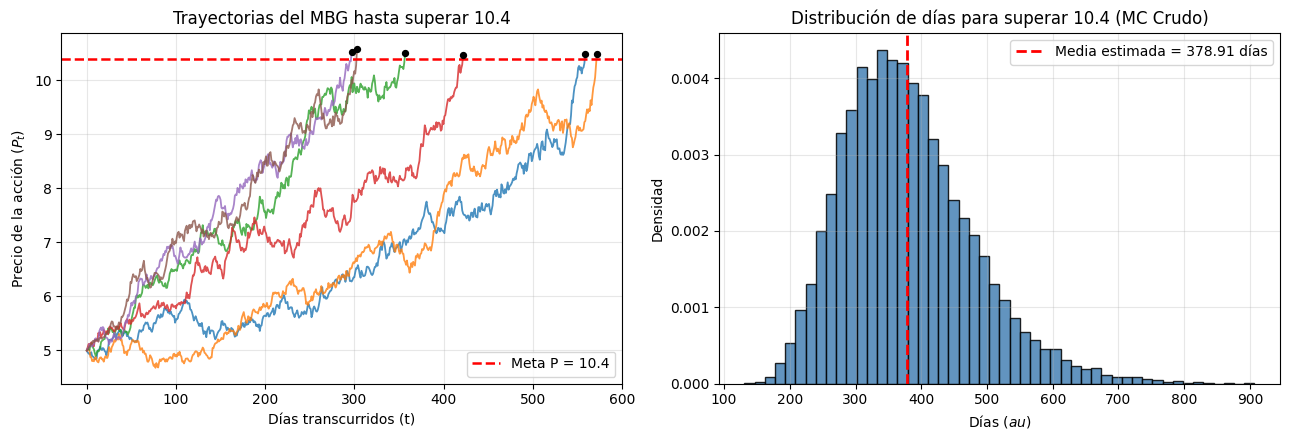

In [67]:
# --- Gráfica Inciso (a): Trayectorias de ejemplo y distribución de días de cruce ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: 6 trayectorias ilustrativas hasta cruzar 10.4
random.seed(10)
drift = mu - 0.5 * (sigma ** 2)
for k in range(6):
    P_hist = [P0]
    P_curr = P0
    while P_curr <= meta:
        P_curr = P_curr * math.exp(drift + sigma * random.gauss(0.0, 1.0))
        P_hist.append(P_curr)
    ax1.plot(range(len(P_hist)), P_hist, alpha=0.8, linewidth=1.3)
    ax1.scatter(len(P_hist) - 1, P_hist[-1], color="black", s=18, zorder=4)

ax1.axhline(meta, color="red", linestyle="--", linewidth=1.8, label=f"Meta P = {meta}")
ax1.set_title("Trayectorias del MBG hasta superar 10.4")
ax1.set_xlabel("Días transcurridos (t)")
ax1.set_ylabel("Precio de la acción ($P_t$)")
ax1.legend()
ax1.grid(alpha=0.3)

# Panel 2: Histograma del tiempo de primer cruce
ax2.hist(dias_mc, bins=50, color="steelblue", edgecolor="black", density=True, alpha=0.85)
ax2.axvline(media_mc, color="red", linestyle="--", linewidth=2, label=f"Media estimada = {media_mc:.2f} días")
ax2.set_title("Distribución de días para superar 10.4 (MC Crudo)")
ax2.set_xlabel("Días ($\tau$)")
ax2.set_ylabel("Densidad")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Inciso B
---

In [68]:
@njit
def simular_antiteticas(N_pares, P0, mu, sigma, meta, semilla=42):
    random.seed(semilla)
    tau_1 = np.empty(N_pares, dtype=np.float64)
    tau_2 = np.empty(N_pares, dtype=np.float64)
    drift = mu - 0.5 * (sigma ** 2)

    for j in range(N_pares):
        P1 = P0
        P2 = P0
        t1 = 0
        t2 = 0

        # Ambas trayectorias comparten los choques opuestos +Z y -Z
        while P1 <= meta or P2 <= meta:
            Z = random.gauss(0.0, 1.0)

            if P1 <= meta:
                P1 = P1 * math.exp(drift + sigma * Z)
                t1 += 1

            if P2 <= meta:
                P2 = P2 * math.exp(drift - sigma * Z)
                t2 += 1

        tau_1[j] = t1
        tau_2[j] = t2

    return tau_1, tau_2

# Ejecución usando N/2 pares (mismo total de N trayectorias)
N_pares = N // 2
tau_1, tau_2 = simular_antiteticas(N_pares, P0, mu, sigma, meta, semilla=42)

Y_ant = 0.5 * (tau_1 + tau_2)
media_ant = np.mean(Y_ant)
var_pares_ant = np.var(Y_ant, ddof=1)
var_est_ant = var_pares_ant / N_pares
red_ant = (1.0 - var_est_ant / var_est_mc) * 100.0
corr_ant = np.corrcoef(tau_1, tau_2)[0, 1]

print(f"Días esperados estimados: {media_ant:.4f}")
print(f"Correlación entre pares:  {corr_ant:.4f}")
print(f"Varianza del estimador:   {var_est_ant:.6f}")
print(f"Reducción de varianza:    {red_ant:.2f}%")

Días esperados estimados: 378.7029
Correlación entre pares:  -0.7948
Varianza del estimador:   0.100912
Reducción de varianza:    79.46%


### Gráficas 
---

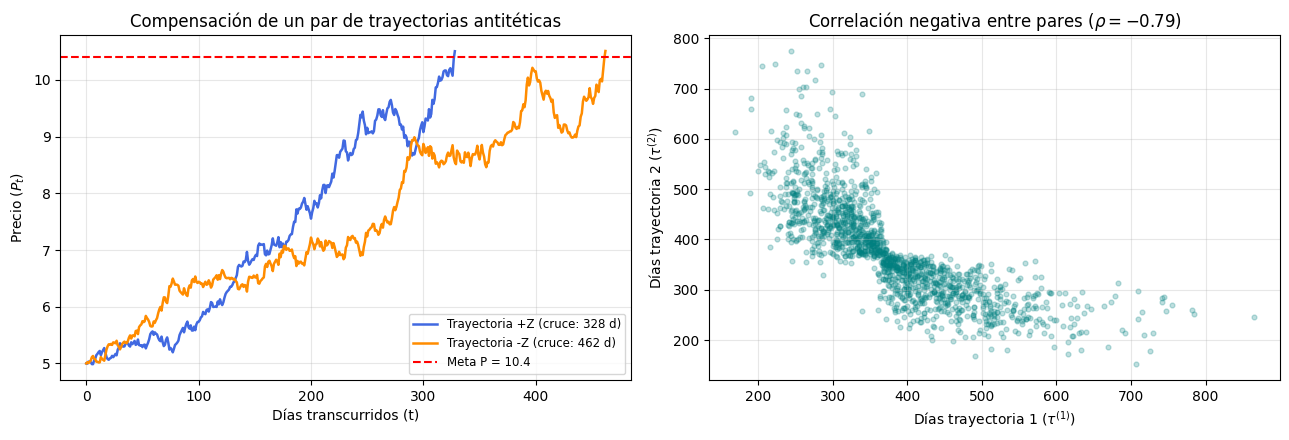

In [69]:

# --- Gráfica Inciso (b): Par antitético y correlación negativa ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: Ejemplo de un par de trayectorias opuestas (+Z vs -Z)
random.seed(7)
drift = mu - 0.5 * (sigma ** 2)
P1_hist, P2_hist = [P0], [P0]
P1_c, P2_c = P0, P0
while P1_c <= meta or P2_c <= meta:
    Z = random.gauss(0.0, 1.0)
    if P1_c <= meta:
        P1_c = P1_c * math.exp(drift + sigma * Z)
        P1_hist.append(P1_c)
    if P2_c <= meta:
        P2_c = P2_c * math.exp(drift - sigma * Z)
        P2_hist.append(P2_c)

ax1.plot(range(len(P1_hist)), P1_hist, color="royalblue", linewidth=1.8, label=f"Trayectoria +Z (cruce: {len(P1_hist)-1} d)")
ax1.plot(range(len(P2_hist)), P2_hist, color="darkorange", linewidth=1.8, label=f"Trayectoria -Z (cruce: {len(P2_hist)-1} d)")
ax1.axhline(meta, color="red", linestyle="--", linewidth=1.5, label=f"Meta P = {meta}")
ax1.set_title("Compensación de un par de trayectorias antitéticas")
ax1.set_xlabel("Días transcurridos (t)")
ax1.set_ylabel("Precio ($P_t$)")
ax1.legend(fontsize=8.5)
ax1.grid(alpha=0.3)

# Panel 2: Dispersión tau_1 vs tau_2 mostrando la correlación negativa
ax2.scatter(tau_1[:1500], tau_2[:1500], alpha=0.25, s=12, color="teal")
ax2.set_title(f"Correlación negativa entre pares ($\\rho = {corr_ant:.2f}$)")
ax2.set_xlabel("Días trayectoria 1 ($\\tau^{(1)}$)")
ax2.set_ylabel("Días trayectoria 2 ($\\tau^{(2)}$)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Inciso C
---

In [70]:
@njit
def simular_control(N, P0, mu, sigma, meta, semilla=42):
    random.seed(semilla)
    dias = np.empty(N, dtype=np.float64)
    W_tau = np.empty(N, dtype=np.float64)
    drift = mu - 0.5 * (sigma ** 2)

    for i in range(N):
        W = 0.0
        t = 0
        P = P0
        while P <= meta:
            Z = random.gauss(0.0, 1.0)
            W += Z
            t += 1
            P = P0 * math.exp(drift * t + sigma * W)
        dias[i] = t
        W_tau[i] = W

    return dias, W_tau

# Ejecución de la simulación con variable de control W_tau
dias_c, W_tau = simular_control(N, P0, mu, sigma, meta, semilla=42)

# Cálculo del coeficiente óptimo c* = Cov(tau, W_tau) / Var(W_tau) con E[W_tau] = 0
cov_matriz = np.cov(dias_c, W_tau, ddof=1)
c_opt = cov_matriz[0, 1] / cov_matriz[1, 1]

Y_cv = dias_c - c_opt * (W_tau - 0.0)
media_cv = np.mean(Y_cv)
var_muestral_cv = np.var(Y_cv, ddof=1)
var_est_cv = var_muestral_cv / N
red_cv = (1.0 - var_est_cv / var_est_mc) * 100.0
corr_cv = np.corrcoef(dias_c, W_tau)[0, 1]

print(f"Días esperados estimados: {media_cv:.4f}")
print(f"Coeficiente óptimo c*:    {c_opt:.4f}")
print(f"Correlación (tau, W_tau): {corr_cv:.5f}")
print(f"Varianza del estimador:   {var_est_cv:.6f}")
print(f"Reducción de varianza:    {red_cv:.2f}%")

Días esperados estimados: 378.8120
Coeficiente óptimo c*:    -5.1249
Correlación (tau, W_tau): -0.99962
Varianza del estimador:   0.000374
Reducción de varianza:    99.92%


### Gráficas 
---

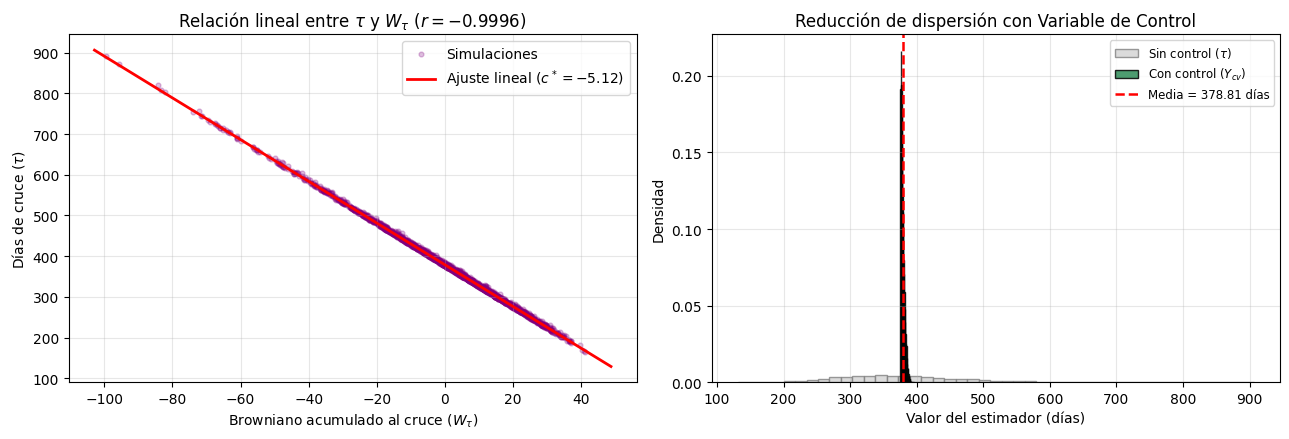

In [71]:
# --- Gráfica Inciso (c): Relación lineal con W_tau y colapso de la dispersión ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: Linealidad entre tau y W_tau
ax1.scatter(W_tau[:2000], dias_c[:2000], alpha=0.25, s=12, color="purple", label="Simulaciones")
w_grid = np.linspace(np.min(W_tau), np.max(W_tau), 100)
ax1.plot(w_grid, media_cv + c_opt * w_grid, color="red", linewidth=2, label=f"Ajuste lineal ($c^* = {c_opt:.2f}$)")
ax1.set_title(f"Relación lineal entre $\\tau$ y $W_\\tau$ ($r = {corr_cv:.4f}$)")
ax1.set_xlabel("Browniano acumulado al cruce ($W_\\tau$)")
ax1.set_ylabel("Días de cruce ($\\tau$)")
ax1.legend()
ax1.grid(alpha=0.3)

# Panel 2: Comparación de dispersión antes y después de aplicar el control
ax2.hist(dias_c, bins=45, color="lightgray", edgecolor="gray", density=True, alpha=0.8, label="Sin control ($\\tau$)")
ax2.hist(Y_cv, bins=35, color="seagreen", edgecolor="black", density=True, alpha=0.85, label="Con control ($Y_{cv}$)")
ax2.axvline(media_cv, color="red", linestyle="--", linewidth=1.8, label=f"Media = {media_cv:.2f} días")
ax2.set_title("Reducción de dispersión con Variable de Control")
ax2.set_xlabel("Valor del estimador (días)")
ax2.set_ylabel("Densidad")
ax2.legend(fontsize=8.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Tabla comparativa

In [72]:
tabla_resultados = [
    [
        "a) Monte Carlo Crudo",
        f"{media_mc:.4f}",
        f"{var_est_mc:.6f}",
        f"{math.sqrt(var_est_mc):.4f}",
        "0.00% (Base)"
    ],
    [
        "b) Variables Antitéticas",
        f"{media_ant:.4f}",
        f"{var_est_ant:.6f}",
        f"{math.sqrt(var_est_ant):.4f}",
        f"{red_ant:.2f}%"
    ],
    [
        "c) Variables de Control (W_tau)",
        f"{media_cv:.4f}",
        f"{var_est_cv:.6f}",
        f"{math.sqrt(var_est_cv):.4f}",
        f"{red_cv:.2f}%"
    ]
]

encabezados = [
    "Método de Simulación",
    "E[tau] Estimado (días)",
    "Varianza del Estimador",
    "Error Estándar",
    "Reducción de Varianza"
]

print(tabulate(tabla_resultados, headers=encabezados, tablefmt="fancy_grid"))

╒═════════════════════════════════╤══════════════════════════╤══════════════════════════╤══════════════════╤═════════════════════════╕
│ Método de Simulación            │   E[tau] Estimado (días) │   Varianza del Estimador │   Error Estándar │ Reducción de Varianza   │
╞═════════════════════════════════╪══════════════════════════╪══════════════════════════╪══════════════════╪═════════════════════════╡
│ a) Monte Carlo Crudo            │                  378.913 │                 0.491263 │           0.7009 │ 0.00% (Base)            │
├─────────────────────────────────┼──────────────────────────┼──────────────────────────┼──────────────────┼─────────────────────────┤
│ b) Variables Antitéticas        │                  378.703 │                 0.100912 │           0.3177 │ 79.46%                  │
├─────────────────────────────────┼──────────────────────────┼──────────────────────────┼──────────────────┼─────────────────────────┤
│ c) Variables de Control (W_tau) │                  37

## Ejercicio 5
---

### Inciso A
---

In [73]:
# Parámetros del problema
umbral = 3.0
N = 100000
valor_real = 0.5 * math.erfc(umbral / math.sqrt(2.0))

@njit
def simular_mc_crudo(N, umbral, semilla=42):
    random.seed(semilla)
    indicadoras = np.empty(N, dtype=np.float64)

    for i in range(N):
        X = random.gauss(0.0, 1.0)
        if X > umbral:
            indicadoras[i] = 1.0
        else:
            indicadoras[i] = 0.0

    return indicadoras

# Ejecución de la simulación base
ind_mc = simular_mc_crudo(N, umbral, semilla=42)

prob_mc = np.mean(ind_mc)
var_muestral_mc = np.var(ind_mc, ddof=1)
var_est_mc = var_muestral_mc / N
ee_mc = math.sqrt(var_est_mc)

print(f"Probabilidad real P(X > 3):   {valor_real:.8f}")
print(f"Probabilidad estimada (MC):   {prob_mc:.8f}")
print(f"Varianza del estimador:       {var_est_mc:.6e}")
print(f"Error estándar:               {ee_mc:.6e}")

Probabilidad real P(X > 3):   0.00134990
Probabilidad estimada (MC):   0.00131000
Varianza del estimador:       1.308297e-08
Error estándar:               1.143808e-04


### Gráficas
---

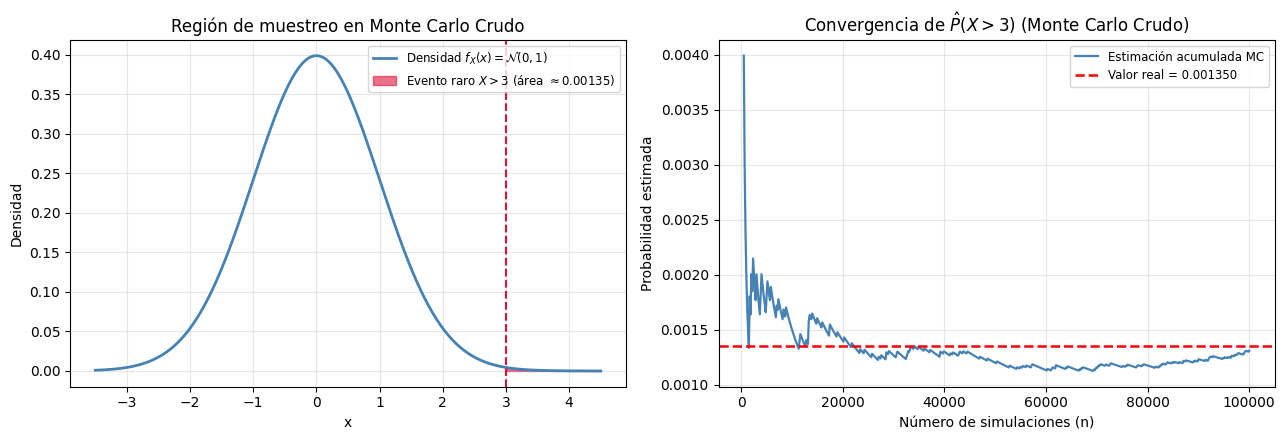

In [74]:
# --- Gráfica Inciso (a): Cola rara de N(0, 1) y convergencia del promedio ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: Densidad N(0, 1) y región del evento raro X > 3
x_grid = np.linspace(-3.5, 4.5, 500)
f_x_grid = (1.0 / math.sqrt(2.0 * math.pi)) * np.exp(-0.5 * (x_grid ** 2))

ax1.plot(x_grid, f_x_grid, color="steelblue", linewidth=2, label="Densidad $f_X(x) = \\mathcal{N}(0, 1)$")
ax1.fill_between(x_grid, f_x_grid, where=(x_grid > umbral), color="crimson", alpha=0.6, label="Evento raro $X > 3$ (área $\\approx 0.00135$)")
ax1.axvline(umbral, color="crimson", linestyle="--", linewidth=1.5)
ax1.set_title("Región de muestreo en Monte Carlo Crudo")
ax1.set_xlabel("x")
ax1.set_ylabel("Densidad")
ax1.legend(fontsize=8.5)
ax1.grid(alpha=0.3)

# Panel 2: Convergencia acumulada de la estimación
n_pasos = np.arange(1, N + 1)
media_acum_mc = np.cumsum(ind_mc) / n_pasos
idx_plot = np.linspace(500, N - 1, 600, dtype=int)

ax2.plot(n_pasos[idx_plot], media_acum_mc[idx_plot], color="steelblue", linewidth=1.6, label="Estimación acumulada MC")
ax2.axhline(valor_real, color="red", linestyle="--", linewidth=1.8, label=f"Valor real = {valor_real:.6f}")
ax2.set_title("Convergencia de $\\hat{P}(X > 3)$ (Monte Carlo Crudo)")
ax2.set_xlabel("Número de simulaciones (n)")
ax2.set_ylabel("Probabilidad estimada")
ax2.legend(fontsize=8.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Inciso B
---

In [75]:
@njit
def evaluar_candidato_is(Z_base, mu, sigma, umbral):
    n = len(Z_base)
    Y = np.empty(n, dtype=np.float64)
    inv_sqrt_2pi = 1.0 / math.sqrt(2.0 * math.pi)
    inv_sigma_sqrt_2pi = 1.0 / (sigma * math.sqrt(2.0 * math.pi))

    for i in range(n):
        X = mu + sigma * Z_base[i]
        if X > umbral:
            f_x = inv_sqrt_2pi * math.exp(-0.5 * (X ** 2))
            h_x = inv_sigma_sqrt_2pi * math.exp(-((X - mu) ** 2) / (2.0 * (sigma ** 2)))
            Y[i] = f_x / h_x
        else:
            Y[i] = 0.0

    return Y

@njit
def simular_is_normal(N, mu, sigma, umbral, semilla=123):
    random.seed(semilla)
    Y = np.empty(N, dtype=np.float64)
    inv_sqrt_2pi = 1.0 / math.sqrt(2.0 * math.pi)
    inv_sigma_sqrt_2pi = 1.0 / (sigma * math.sqrt(2.0 * math.pi))

    for i in range(N):
        Z = random.gauss(0.0, 1.0)
        X = mu + sigma * Z

        # Definición directa: Y = g(X) * f_X(X) / h(X)
        if X > umbral:
            f_x = inv_sqrt_2pi * math.exp(-0.5 * (X ** 2))
            h_x = inv_sigma_sqrt_2pi * math.exp(-((X - mu) ** 2) / (2.0 * (sigma ** 2)))
            Y[i] = f_x / h_x
        else:
            Y[i] = 0.0

    return Y

# 1. Búsqueda de mejores parámetros (respetando sigma > 1/sqrt(2) ~ 0.7071)
np.random.seed(7)
Z_busqueda = np.random.normal(0.0, 1.0, N)

mus = [2.8, 3.0, 3.2, 3.3, 3.4, 3.5, 3.6]
sigmas = [0.75, 0.80, 0.85, 0.90, 0.95, 1.00, 1.10]

mejor_var_muestral = float("inf")
mejor_mu, mejor_sigma = 0.0, 0.0

for mu_p in mus:
    for sigma_p in sigmas:
        Y_cand = evaluar_candidato_is(Z_busqueda, mu_p, sigma_p, umbral)
        var_temp = np.var(Y_cand, ddof=1)
        if var_temp < mejor_var_muestral:
            mejor_var_muestral = var_temp
            mejor_mu, mejor_sigma = mu_p, sigma_p

print(f"Mejores parámetros -> mu = {mejor_mu}, sigma = {mejor_sigma}")

# 2. Simulación final independiente con los parámetros óptimos
Y_is = simular_is_normal(N, mejor_mu, mejor_sigma, umbral, semilla=123)

prob_is = np.mean(Y_is)
var_muestral_is = np.var(Y_is, ddof=1)
var_est_is = var_muestral_is / N
ee_is = math.sqrt(var_est_is)
red_is = (1.0 - var_est_is / var_est_mc) * 100.0

print(f"Probabilidad real P(X > 3):   {valor_real:.8f}")
print(f"Probabilidad estimada (IS):   {prob_is:.8f}")
print(f"Varianza del estimador:       {var_est_is:.6e}")
print(f"Error estándar:               {ee_is:.6e}")
print(f"Reducción de varianza:        {red_is:.2f}%")

Mejores parámetros -> mu = 3.2, sigma = 0.75
Probabilidad real P(X > 3):   0.00134990
Probabilidad estimada (IS):   0.00134571
Varianza del estimador:       4.141573e-11
Error estándar:               6.435505e-06
Reducción de varianza:        99.68%


### Gráficas
---

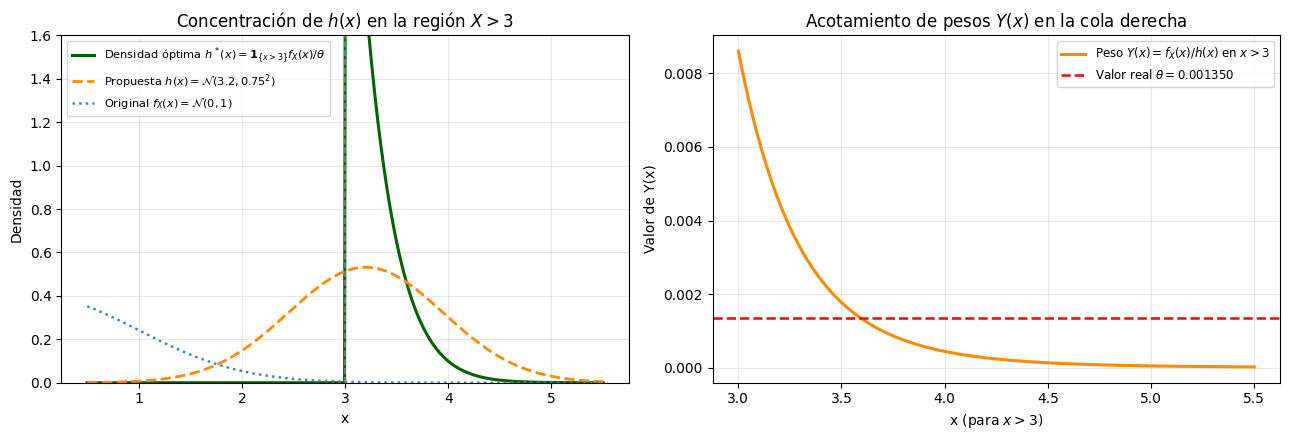

In [76]:
# --- Gráfica Inciso (b): Densidad auxiliar h(x) y comportamiento de Y(x) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

x_grid_is = np.linspace(0.5, 5.5, 500)
f_x_is = (1.0 / math.sqrt(2.0 * math.pi)) * np.exp(-0.5 * (x_grid_is ** 2))
h_x_is = (1.0 / (mejor_sigma * math.sqrt(2.0 * math.pi))) * np.exp(-((x_grid_is - mejor_mu) ** 2) / (2.0 * (mejor_sigma ** 2)))
h_optima = np.where(x_grid_is > umbral, f_x_is / valor_real, 0.0)

# Panel 1: Ajuste de la propuesta Normal h(x) respecto a la forma óptima h*(x)
ax1.plot(x_grid_is, h_optima, color="darkgreen", linewidth=2.2, label="Densidad óptima $h^*(x) = \\mathbf{1}_{\\{x>3\\}}f_X(x)/\\theta$")
ax1.plot(x_grid_is, h_x_is, color="darkorange", linestyle="--", linewidth=2.0, label=f"Propuesta $h(x) = \\mathcal{{N}}({mejor_mu}, {mejor_sigma}^2)$")
ax1.plot(x_grid_is, f_x_is, color="steelblue", linestyle=":", linewidth=1.8, label="Original $f_X(x) = \\mathcal{N}(0, 1)$")
ax1.axvline(umbral, color="gray", linestyle="--", linewidth=1.2)
ax1.set_title("Concentración de $h(x)$ en la región $X > 3$")
ax1.set_xlabel("x")
ax1.set_ylabel("Densidad")
ax1.set_ylim(0, 1.6)
ax1.legend(fontsize=8.2)
ax1.grid(alpha=0.3)

# Panel 2: Estabilidad del estimador Y(x) = g(x)*f_X(x)/h(x) para x > 3
x_cola = np.linspace(3.001, 5.5, 300)
f_cola = (1.0 / math.sqrt(2.0 * math.pi)) * np.exp(-0.5 * (x_cola ** 2))
h_cola = (1.0 / (mejor_sigma * math.sqrt(2.0 * math.pi))) * np.exp(-((x_cola - mejor_mu) ** 2) / (2.0 * (mejor_sigma ** 2)))
Y_curva = f_cola / h_cola

ax2.plot(x_cola, Y_curva, color="darkorange", linewidth=2.2, label="Peso $Y(x) = f_X(x)/h(x)$ en $x > 3$")
ax2.axhline(valor_real, color="red", linestyle="--", linewidth=1.8, label=f"Valor real $\\theta = {valor_real:.6f}$")
ax2.set_title("Acotamiento de pesos $Y(x)$ en la cola derecha")
ax2.set_xlabel("x (para $x > 3$)")
ax2.set_ylabel("Valor de Y(x)")
ax2.legend(fontsize=8.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Tabla comparativa

In [77]:
tabla_resultados = [
    [
        "a) Monte Carlo Crudo",
        f"{prob_mc:.8f}",
        f"{valor_real:.8f}",
        f"{var_est_mc:.6e}",
        f"{ee_mc:.6e}",
        "0.00% (Base)"
    ],
    [
        f"b) Muestreo Importancia N({mejor_mu}, {mejor_sigma}^2)",
        f"{prob_is:.8f}",
        f"{valor_real:.8f}",
        f"{var_est_is:.6e}",
        f"{ee_is:.6e}",
        f"{red_is:.2f}%"
    ]
]

encabezados = [
    "Método de Simulación",
    "P(X > 3) Estimado",
    "Valor Real",
    "Varianza del Estimador",
    "Error Estándar",
    "Reducción de Varianza"
]

print(tabulate(tabla_resultados, headers=encabezados, tablefmt="fancy_grid"))

╒════════════════════════════════════════╤═════════════════════╤══════════════╤══════════════════════════╤══════════════════╤═════════════════════════╕
│ Método de Simulación                   │   P(X > 3) Estimado │   Valor Real │   Varianza del Estimador │   Error Estándar │ Reducción de Varianza   │
╞════════════════════════════════════════╪═════════════════════╪══════════════╪══════════════════════════╪══════════════════╪═════════════════════════╡
│ a) Monte Carlo Crudo                   │          0.00131    │    0.0013499 │              1.3083e-08  │      0.000114381 │ 0.00% (Base)            │
├────────────────────────────────────────┼─────────────────────┼──────────────┼──────────────────────────┼──────────────────┼─────────────────────────┤
│ b) Muestreo Importancia N(3.2, 0.75^2) │          0.00134571 │    0.0013499 │              4.14157e-11 │      6.4355e-06  │ 99.68%                  │
╘════════════════════════════════════════╧═════════════════════╧══════════════╧═════════

## Ejercicio 6
---

### Inciso A
---

In [79]:
# Parámetros del problema
lam_x = 1.0
lam_y = 2.0
umbral = 5.0
N = 100000
valor_real = 2.0 * math.exp(-5.0) - math.exp(-10.0)

@njit
def simular_mc_crudo(N, lam_x, lam_y, umbral, semilla=42):
    random.seed(semilla)
    indicadoras = np.empty(N, dtype=np.float64)
    X_muestra = np.empty(N, dtype=np.float64)
    Y_muestra = np.empty(N, dtype=np.float64)

    for i in range(N):
        u1 = random.random()
        u2 = random.random()

        x = -math.log(1.0 - u1) / lam_x
        y = -math.log(1.0 - u2) / lam_y

        X_muestra[i] = x
        Y_muestra[i] = y

        if x + y > umbral:
            indicadoras[i] = 1.0
        else:
            indicadoras[i] = 0.0

    return indicadoras, X_muestra, Y_muestra

# Ejecución de la simulación base
ind_mc, X_sim, Y_sim = simular_mc_crudo(N, lam_x, lam_y, umbral, semilla=42)

prob_mc = np.mean(ind_mc)
var_muestral_mc = np.var(ind_mc, ddof=1)
var_est_mc = var_muestral_mc / N
ee_mc = math.sqrt(var_est_mc)

print(f"Probabilidad real P(X + Y > 5): {valor_real:.8f}")
print(f"Probabilidad estimada (MC):     {prob_mc:.8f}")
print(f"Varianza del estimador:         {var_est_mc:.6e}")
print(f"Error estándar:                 {ee_mc:.6e}")

Probabilidad real P(X + Y > 5): 0.01343049
Probabilidad estimada (MC):     0.01341000
Varianza del estimador:         1.323030e-07
Error estándar:                 3.637349e-04


### Gráficas
---

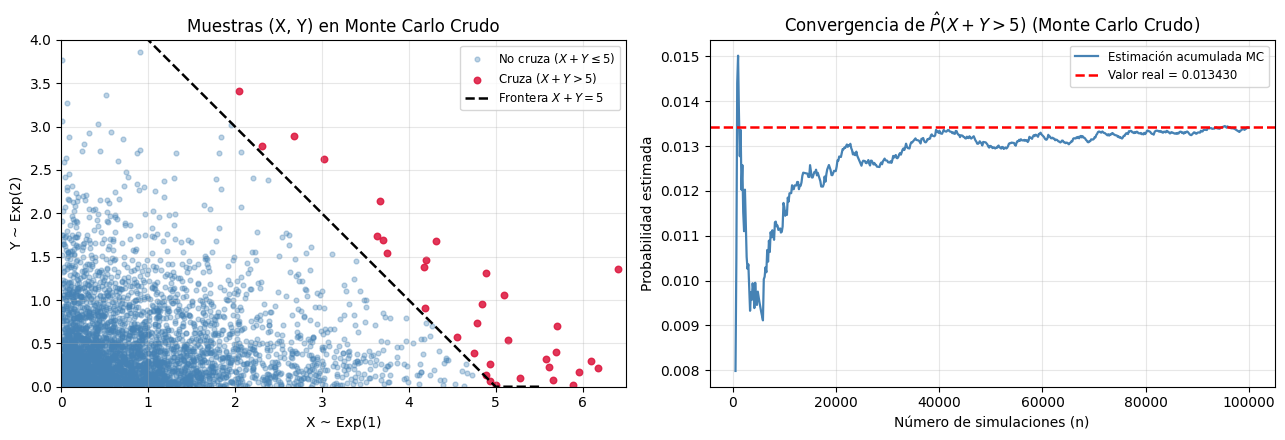

In [80]:

# --- Gráfica Inciso (a): Región de cruce X + Y > 5 y convergencia ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: Nube de puntos (X, Y) y frontera X + Y = 5
n_vis = 4000
x_vis = X_sim[:n_vis]
y_vis = Y_sim[:n_vis]
dentro = (x_vis + y_vis) > umbral

ax1.scatter(x_vis[~dentro], y_vis[~dentro], color="steelblue", alpha=0.35, s=12, label="No cruza ($X + Y \\leq 5$)")
ax1.scatter(x_vis[dentro], y_vis[dentro], color="crimson", alpha=0.85, s=22, label="Cruza ($X + Y > 5$)")
x_linea = np.linspace(0, 5.5, 200)
ax1.plot(x_linea, np.maximum(0, umbral - x_linea), color="black", linestyle="--", linewidth=1.8, label="Frontera $X + Y = 5$")
ax1.set_xlim(0, 6.5)
ax1.set_ylim(0, 4.0)
ax1.set_title("Muestras (X, Y) en Monte Carlo Crudo")
ax1.set_xlabel("X ~ Exp(1)")
ax1.set_ylabel("Y ~ Exp(2)")
ax1.legend(fontsize=8.5)
ax1.grid(alpha=0.3)

# Panel 2: Convergencia acumulada de la estimación cruda
n_pasos = np.arange(1, N + 1)
media_acum_mc = np.cumsum(ind_mc) / n_pasos
idx_plot = np.linspace(500, N - 1, 600, dtype=int)

ax2.plot(n_pasos[idx_plot], media_acum_mc[idx_plot], color="steelblue", linewidth=1.6, label="Estimación acumulada MC")
ax2.axhline(valor_real, color="red", linestyle="--", linewidth=1.8, label=f"Valor real = {valor_real:.6f}")
ax2.set_title("Convergencia de $\\hat{P}(X + Y > 5)$ (Monte Carlo Crudo)")
ax2.set_xlabel("Número de simulaciones (n)")
ax2.set_ylabel("Probabilidad estimada")
ax2.legend(fontsize=8.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Inciso B
---

In [81]:
@njit
def simular_condicionamiento(N, lam_y, umbral, semilla=42):
    random.seed(semilla)
    estimaciones = np.empty(N, dtype=np.float64)
    Y_muestra = np.empty(N, dtype=np.float64)

    for i in range(N):
        u = random.random()
        y = -math.log(1.0 - u) / lam_y
        Y_muestra[i] = y

        # Evaluamos h(Y) = E[I_{X + Y > 5} | Y] = P(X > 5 - Y | Y)
        if y >= umbral:
            estimaciones[i] = 1.0
        else:
            estimaciones[i] = math.exp(-(umbral - y))

    return estimaciones, Y_muestra

# Ejecución de la simulación condicionando en Y
est_cond, Y_cond = simular_condicionamiento(N, lam_y, umbral, semilla=42)

prob_cond = np.mean(est_cond)
var_muestral_cond = np.var(est_cond, ddof=1)
var_est_cond = var_muestral_cond / N
ee_cond = math.sqrt(var_est_cond)
red_cond = (1.0 - var_est_cond / var_est_mc) * 100.0

print(f"Probabilidad real P(X + Y > 5): {valor_real:.8f}")
print(f"Probabilidad estimada (Cond):   {prob_cond:.8f}")
print(f"Varianza del estimador:         {var_est_cond:.6e}")
print(f"Error estándar:                 {ee_cond:.6e}")
print(f"Reducción de varianza:          {red_cond:.2f}%")

Probabilidad real P(X + Y > 5): 0.01343049
Probabilidad estimada (Cond):   0.01335825
Varianza del estimador:         3.000586e-09
Error estándar:                 5.477761e-05
Reducción de varianza:          97.73%


### Gráficas 
---

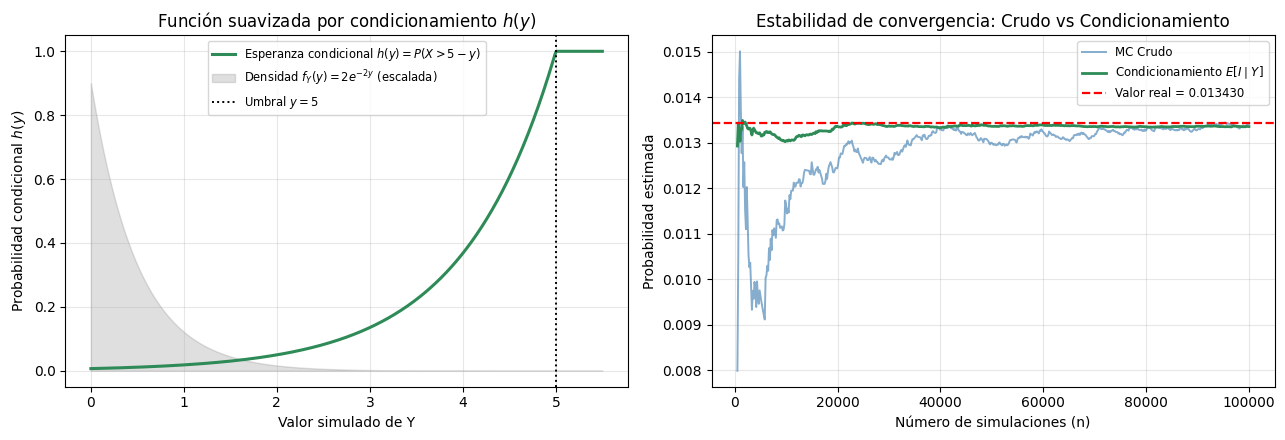

In [82]:

# --- Gráfica Inciso (b): Curva condicional h(y) y comparación de convergencia ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: Función condicional h(y) = P(X + Y > 5 | Y = y) vs densidad f_Y(y)
y_grid = np.linspace(0.0, 5.5, 400)
h_y_grid = np.where(y_grid >= umbral, 1.0, np.exp(-(umbral - y_grid)))
f_y_grid = lam_y * np.exp(-lam_y * y_grid)

ax1.plot(y_grid, h_y_grid, color="seagreen", linewidth=2.2, label="Esperanza condicional $h(y) = P(X > 5 - y)$")
ax1.fill_between(y_grid, 0, f_y_grid * 0.45, color="gray", alpha=0.25, label="Densidad $f_Y(y) = 2e^{-2y}$ (escalada)")
ax1.axvline(umbral, color="black", linestyle=":", linewidth=1.4, label="Umbral $y = 5$")
ax1.set_title("Función suavizada por condicionamiento $h(y)$")
ax1.set_xlabel("Valor simulado de Y")
ax1.set_ylabel("Probabilidad condicional $h(y)$")
ax1.legend(fontsize=8.3)
ax1.grid(alpha=0.3)

# Panel 2: Comparación de estabilidad en la convergencia (MC Crudo vs Condicionamiento)
media_acum_cond = np.cumsum(est_cond) / n_pasos

ax2.plot(n_pasos[idx_plot], media_acum_mc[idx_plot], color="steelblue", alpha=0.65, linewidth=1.4, label="MC Crudo")
ax2.plot(n_pasos[idx_plot], media_acum_cond[idx_plot], color="seagreen", linewidth=2.0, label="Condicionamiento $E[I \\mid Y]$")
ax2.axhline(valor_real, color="red", linestyle="--", linewidth=1.6, label=f"Valor real = {valor_real:.6f}")
ax2.set_title("Estabilidad de convergencia: Crudo vs Condicionamiento")
ax2.set_xlabel("Número de simulaciones (n)")
ax2.set_ylabel("Probabilidad estimada")
ax2.legend(fontsize=8.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Tabla compartiva

In [83]:
tabla_resultados = [
    [
        "a) Monte Carlo Crudo",
        f"{prob_mc:.8f}",
        f"{valor_real:.8f}",
        f"{var_est_mc:.6e}",
        f"{ee_mc:.6e}",
        "0.00% (Base)"
    ],
    [
        "b) Condicionamiento E[I | Y]",
        f"{prob_cond:.8f}",
        f"{valor_real:.8f}",
        f"{var_est_cond:.6e}",
        f"{ee_cond:.6e}",
        f"{red_cond:.2f}%"
    ]
]

encabezados = [
    "Método de Simulación",
    "P(X + Y > 5) Estimado",
    "Valor Real",
    "Varianza del Estimador",
    "Error Estándar",
    "Reducción de Varianza"
]

print(tabulate(tabla_resultados, headers=encabezados, tablefmt="fancy_grid"))

╒══════════════════════════════╤═════════════════════════╤══════════════╤══════════════════════════╤══════════════════╤═════════════════════════╕
│ Método de Simulación         │   P(X + Y > 5) Estimado │   Valor Real │   Varianza del Estimador │   Error Estándar │ Reducción de Varianza   │
╞══════════════════════════════╪═════════════════════════╪══════════════╪══════════════════════════╪══════════════════╪═════════════════════════╡
│ a) Monte Carlo Crudo         │               0.01341   │    0.0134305 │              1.32303e-07 │      0.000363735 │ 0.00% (Base)            │
├──────────────────────────────┼─────────────────────────┼──────────────┼──────────────────────────┼──────────────────┼─────────────────────────┤
│ b) Condicionamiento E[I | Y] │               0.0133583 │    0.0134305 │              3.00059e-09 │      5.47776e-05 │ 97.73%                  │
╘══════════════════════════════╧═════════════════════════╧══════════════╧══════════════════════════╧══════════════════╧═════

## Ejercicio 7
---

### Inciso A
---

In [88]:
# Parámetros del problema
umbral = 2.0
N = 1000000
valor_real = 0.5 * (1.0 + math.exp(-2.0))

@njit
def simular_mc_crudo(N, umbral, semilla=42):
    random.seed(semilla)
    indicadoras = np.empty(N, dtype=np.float64)
    X_muestra = np.empty(N, dtype=np.float64)
    Y_muestra = np.empty(N, dtype=np.float64)

    for i in range(N):
        u1 = random.random()
        u2 = random.random()

        # Transformada inversa para X ~ f(x)=x/2 en [0, 2] y Y ~ Exp(1)
        x = 2.0 * math.sqrt(u1)
        y = -math.log(1.0 - u2)

        X_muestra[i] = x
        Y_muestra[i] = y

        if x + y > umbral:
            indicadoras[i] = 1.0
        else:
            indicadoras[i] = 0.0

    return indicadoras, X_muestra, Y_muestra

# Ejecución de la simulación base
ind_mc, X_sim, Y_sim = simular_mc_crudo(N, umbral, semilla=42)

prob_mc = np.mean(ind_mc)
var_muestral_mc = np.var(ind_mc, ddof=1)
var_est_mc = var_muestral_mc / N
ee_mc = math.sqrt(var_est_mc)

print(f"Probabilidad real P(X + Y > 2): {valor_real:.8f}")
print(f"Probabilidad estimada (MC):     {prob_mc:.8f}")
print(f"Varianza del estimador:         {var_est_mc:.6e}")
print(f"Error estándar:                 {ee_mc:.6e}")

Probabilidad real P(X + Y > 2): 0.56766764
Probabilidad estimada (MC):     0.56754900
Varianza del estimador:         2.454374e-07
Error estándar:                 4.954164e-04


### Gráficas
---

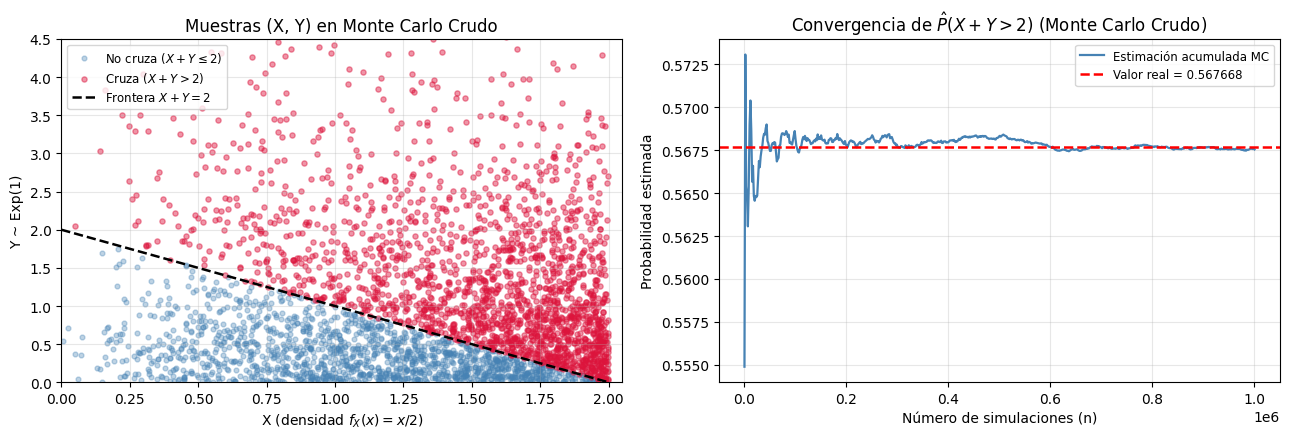

In [89]:
# --- Gráfica Inciso (a): Región de cruce X + Y > 2 y convergencia ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: Puntos simulados (X, Y) y recta frontera X + Y = 2
n_vis = 3500
x_vis = X_sim[:n_vis]
y_vis = Y_sim[:n_vis]
cruza = (x_vis + y_vis) > umbral

ax1.scatter(x_vis[~cruza], y_vis[~cruza], color="steelblue", alpha=0.35, s=12, label="No cruza ($X + Y \\leq 2$)")
ax1.scatter(x_vis[cruza], y_vis[cruza], color="crimson", alpha=0.45, s=14, label="Cruza ($X + Y > 2$)")
x_linea = np.linspace(0.0, 2.0, 200)
ax1.plot(x_linea, umbral - x_linea, color="black", linestyle="--", linewidth=1.8, label="Frontera $X + Y = 2$")
ax1.set_xlim(0.0, 2.05)
ax1.set_ylim(0.0, 4.5)
ax1.set_title("Muestras (X, Y) en Monte Carlo Crudo")
ax1.set_xlabel("X (densidad $f_X(x) = x/2$)")
ax1.set_ylabel("Y ~ Exp(1)")
ax1.legend(fontsize=8.5)
ax1.grid(alpha=0.3)

# Panel 2: Convergencia acumulada de la estimación
n_pasos = np.arange(1, N + 1)
media_acum_mc = np.cumsum(ind_mc) / n_pasos
idx_plot = np.linspace(500, N - 1, 600, dtype=int)

ax2.plot(n_pasos[idx_plot], media_acum_mc[idx_plot], color="steelblue", linewidth=1.6, label="Estimación acumulada MC")
ax2.axhline(valor_real, color="red", linestyle="--", linewidth=1.8, label=f"Valor real = {valor_real:.6f}")
ax2.set_title("Convergencia de $\\hat{P}(X + Y > 2)$ (Monte Carlo Crudo)")
ax2.set_xlabel("Número de simulaciones (n)")
ax2.set_ylabel("Probabilidad estimada")
ax2.legend(fontsize=8.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Inciso B
---

In [90]:
@njit
def simular_condicionamiento(N, umbral, semilla=42):
    random.seed(semilla)
    estimaciones = np.empty(N, dtype=np.float64)
    Y_muestra = np.empty(N, dtype=np.float64)

    for i in range(N):
        u = random.random()
        y = -math.log(1.0 - u)
        Y_muestra[i] = y

        # Evaluamos h(Y) = E[I | Y] = P(X > 2 - Y | Y)
        if y >= umbral:
            estimaciones[i] = 1.0
        else:
            estimaciones[i] = 1.0 - ((umbral - y) ** 2) / 4.0

    return estimaciones, Y_muestra

# Ejecución de la simulación por condicionamiento
est_cond, Y_cond = simular_condicionamiento(N, umbral, semilla=42)

prob_cond = np.mean(est_cond)
var_muestral_cond = np.var(est_cond, ddof=1)
var_est_cond = var_muestral_cond / N
ee_cond = math.sqrt(var_est_cond)
red_cond = (1.0 - var_est_cond / var_est_mc) * 100.0

print(f"Probabilidad real P(X + Y > 2): {valor_real:.8f}")
print(f"Probabilidad estimada (Cond):   {prob_cond:.8f}")
print(f"Varianza del estimador:         {var_est_cond:.6e}")
print(f"Error estándar:                 {ee_cond:.6e}")
print(f"Reducción de varianza:          {red_cond:.2f}%")

Probabilidad real P(X + Y > 2): 0.56766764
Probabilidad estimada (Cond):   0.56804153
Varianza del estimador:         1.100060e-07
Error estándar:                 3.316716e-04
Reducción de varianza:          55.18%


### Gráficas
---

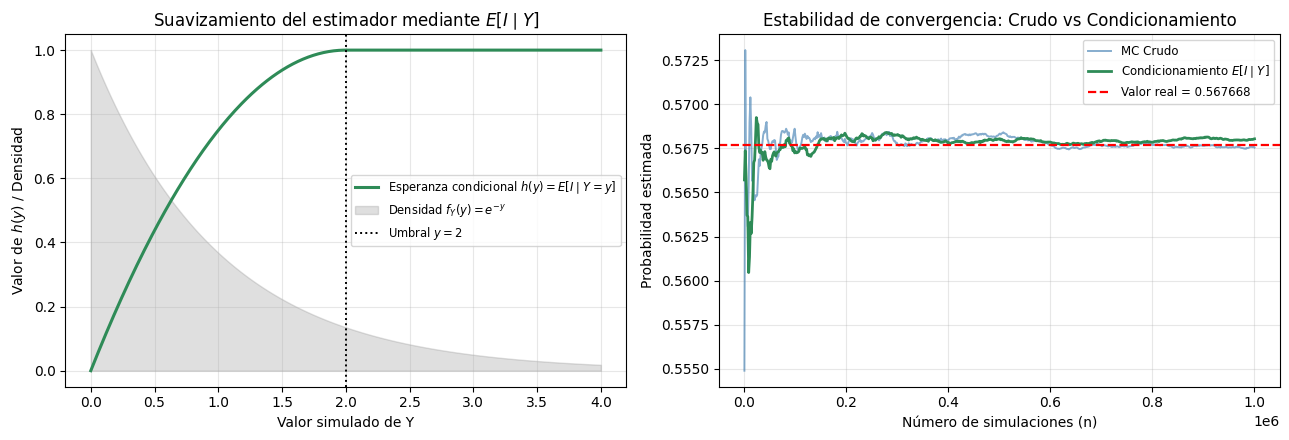

In [ ]:
# --- Gráfica Inciso (b): Función condicional h(y) y dispersión ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: Esperanza condicional h(y) = P(X > 2 - y) vs densidad de Y
y_grid = np.linspace(0.0, 4.0, 400)
h_y_grid = np.where(y_grid >= umbral, 1.0, 1.0 - ((umbral - y_grid) ** 2) / 4.0)
f_y_grid = np.exp(-y_grid)

ax1.plot(y_grid, h_y_grid, color="seagreen", linewidth=2.2, label="Esperanza condicional $h(y) = E[I \\mid Y = y]$")
ax1.fill_between(y_grid, 0.0, f_y_grid, color="gray", alpha=0.25, label="Densidad $f_Y(y) = e^{-y}$")
ax1.axvline(umbral, color="black", linestyle=":", linewidth=1.4, label="Umbral $y = 2$")
ax1.set_title("Suavizamiento del estimador mediante $E[I \\mid Y]$")
ax1.set_xlabel("Valor simulado de Y")
ax1.set_ylabel("Valor de $h(y)$ / Densidad")
ax1.legend(fontsize=8.3)
ax1.grid(alpha=0.3)

# Panel 2: Comparación de convergencia (MC Crudo vs Condicionamiento)
media_acum_cond = np.cumsum(est_cond) / n_pasos

ax2.plot(n_pasos[idx_plot], media_acum_mc[idx_plot], color="steelblue", alpha=0.65, linewidth=1.4, label="MC Crudo")
ax2.plot(n_pasos[idx_plot], media_acum_cond[idx_plot], color="seagreen", linewidth=2.0, label="Condicionamiento $E[I \\mid Y]$")
ax2.axhline(valor_real, color="red", linestyle="--", linewidth=1.6, label=f"Valor real = {valor_real:.6f}")
ax2.set_title("Estabilidad de convergencia: Crudo vs Condicionamiento")
ax2.set_xlabel("Número de simulaciones (n)")
ax2.set_ylabel("Probabilidad estimada")
ax2.legend(fontsize=8.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Inciso C
---

In [94]:
@njit
def simular_control(N, umbral, semilla=42):
    random.seed(semilla)
    indicadoras = np.empty(N, dtype=np.float64)
    suma_XY = np.empty(N, dtype=np.float64)

    for i in range(N):
        u1 = random.random()
        u2 = random.random()

        x = 2.0 * math.sqrt(u1)
        y = -math.log(1.0 - u2)
        total = x + y

        suma_XY[i] = total
        if total > umbral:
            indicadoras[i] = 1.0
        else:
            indicadoras[i] = 0.0

    return indicadoras, suma_XY

# Ejecución de la simulación con variable de control C = X + Y
ind_c, C_sim = simular_control(N, umbral, semilla=42)

# Valor esperado analítico de la variable de control: E[X + Y] = 4/3 + 1 = 7/3
mu_control = (4.0 / 3.0) + 1.0

# Coeficiente óptimo c* = Cov(I, X + Y) / Var(X + Y)
cov_matriz = np.cov(ind_c, C_sim, ddof=1)
c_opt = cov_matriz[0, 1] / cov_matriz[1, 1]
corr_cv = np.corrcoef(ind_c, C_sim)[0, 1]

# Estimador ajustado por control
W_cv = ind_c - c_opt * (C_sim - mu_control)

prob_cv = np.mean(W_cv)
var_muestral_cv = np.var(W_cv, ddof=1)
var_est_cv = var_muestral_cv / N
ee_cv = math.sqrt(var_est_cv)
red_cv = (1.0 - var_est_cv / var_est_mc) * 100.0
print(f"Probabilidad real P(X + Y > 2): {valor_real:.8f}")
print(f"Probabilidad estimada (CV):     {prob_cv:.8f}")
print(f"Coeficiente óptimo c*:          {c_opt:.4f}")
print(f"Correlación (I, X + Y):         {corr_cv:.4f}")
print(f"Varianza del estimador:         {var_est_cv:.6e}")
print(f"Reducción de varianza:          {red_cv:.2f}%")

Probabilidad real P(X + Y > 2): 0.56766764
Probabilidad estimada (CV):     0.56754090
Coeficiente óptimo c*:          0.3089
Correlación (I, X + Y):         0.6904
Varianza del estimador:         1.284423e-07
Reducción de varianza:          47.67%


### Gráfica 
---

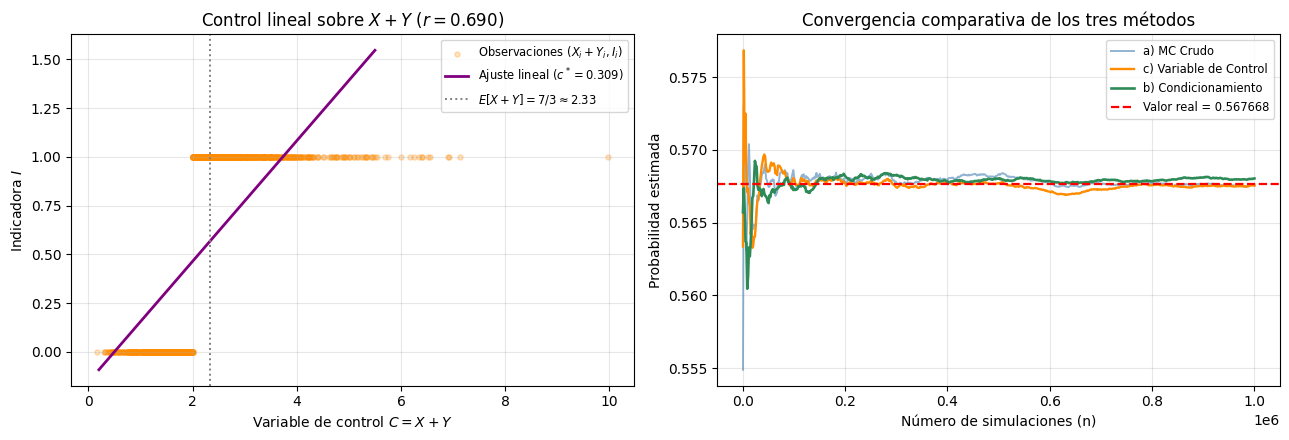

In [95]:
# --- Gráfica Inciso (c): Ajuste lineal de control y comparación global ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Panel 1: Relación entre C = X + Y y la indicadora I = 1_{X + Y > 2}
n_sub = 1200
c_sub = C_sim[:n_sub]
i_sub = ind_c[:n_sub]
c_grid = np.linspace(0.2, 5.5, 200)

ax1.scatter(c_sub, i_sub, alpha=0.25, s=14, color="darkorange", label="Observaciones $(X_i + Y_i, I_i)$")
ax1.plot(c_grid, prob_cv + c_opt * (c_grid - mu_control), color="purple", linewidth=2.0, label=f"Ajuste lineal ($c^* = {c_opt:.3f}$)")
ax1.axvline(mu_control, color="gray", linestyle=":", linewidth=1.4, label=f"$E[X+Y] = 7/3 \\approx {mu_control:.2f}$")
ax1.set_title(f"Control lineal sobre $X + Y$ ($r = {corr_cv:.3f}$)")
ax1.set_xlabel("Variable de control $C = X + Y$")
ax1.set_ylabel("Indicadora $I$")
ax1.legend(fontsize=8.3)
ax1.grid(alpha=0.3)

# Panel 2: Convergencia acumulada comparando los 3 métodos
media_acum_cv = np.cumsum(W_cv) / n_pasos

ax2.plot(n_pasos[idx_plot], media_acum_mc[idx_plot], color="steelblue", alpha=0.6, linewidth=1.4, label="a) MC Crudo")
ax2.plot(n_pasos[idx_plot], media_acum_cv[idx_plot], color="darkorange", linewidth=1.7, label="c) Variable de Control")
ax2.plot(n_pasos[idx_plot], media_acum_cond[idx_plot], color="seagreen", linewidth=1.9, label="b) Condicionamiento")
ax2.axhline(valor_real, color="red", linestyle="--", linewidth=1.6, label=f"Valor real = {valor_real:.6f}")
ax2.set_title("Convergencia comparativa de los tres métodos")
ax2.set_xlabel("Número de simulaciones (n)")
ax2.set_ylabel("Probabilidad estimada")
ax2.legend(fontsize=8.3)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Tabla comparativa

In [96]:
tabla_resultados = [
    [
        "a) Monte Carlo Crudo",
        f"{prob_mc:.8f}",
        f"{valor_real:.8f}",
        f"{var_est_mc:.6e}",
        f"{ee_mc:.6e}",
        "0.00% (Base)"
    ],
    [
        "b) Condicionamiento E[I | Y]",
        f"{prob_cond:.8f}",
        f"{valor_real:.8f}",
        f"{var_est_cond:.6e}",
        f"{ee_cond:.6e}",
        f"{red_cond:.2f}%"
    ],
    [
        "c) Variable de Control (X + Y)",
        f"{prob_cv:.8f}",
        f"{valor_real:.8f}",
        f"{var_est_cv:.6e}",
        f"{ee_cv:.6e}",
        f"{red_cv:.2f}%"
    ]
]

encabezados = [
    "Método de Simulación",
    "P(X + Y > 2) Estimado",
    "Valor Real",
    "Varianza del Estimador",
    "Error Estándar",
    "Reducción de Varianza"
]

print(tabulate(tabla_resultados, headers=encabezados, tablefmt="fancy_grid"))

╒════════════════════════════════╤═════════════════════════╤══════════════╤══════════════════════════╤══════════════════╤═════════════════════════╕
│ Método de Simulación           │   P(X + Y > 2) Estimado │   Valor Real │   Varianza del Estimador │   Error Estándar │ Reducción de Varianza   │
╞════════════════════════════════╪═════════════════════════╪══════════════╪══════════════════════════╪══════════════════╪═════════════════════════╡
│ a) Monte Carlo Crudo           │                0.567549 │     0.567668 │              2.45437e-07 │      0.000495416 │ 0.00% (Base)            │
├────────────────────────────────┼─────────────────────────┼──────────────┼──────────────────────────┼──────────────────┼─────────────────────────┤
│ b) Condicionamiento E[I | Y]   │                0.568042 │     0.567668 │              1.10006e-07 │      0.000331672 │ 55.18%                  │
├────────────────────────────────┼─────────────────────────┼──────────────┼──────────────────────────┼──────────